<a href="https://colab.research.google.com/github/AM0ya/Clase_Programacion/blob/main/Actividad_EDA_predictivo_bank_marketing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** Alfredo Moya Orozco  

**Matrícula:** 269712

**Fecha:** 11/10/2026

## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |

## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [1]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
COLORES_CLASE = {"no": AZUL, "yes": NARANJA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

# df.head()

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación? |Un contacto telefonico (posible cliente) |
| ¿Qué se predice? |si el cliente contratará el depósito a plazo (y)  |
| ¿Qué tipo de problema es? |Clasificacion Binaria |
| ¿En qué momento se haría la predicción y qué información existiría entonces? |La prediccion se realizaria despues de que se haya hecho contacto con el cliente, y la informacion seria 'pdays & poutcome'|
| ¿Qué columnas no deberían usarse como características y por qué? |'Contact' No deberia usarse ya que solo es el medio por el cual se contacta. month, day_of_week tampoco deberian representar una caracteristica fundamental. |

**Tu predicción.** ¿Qué porcentaje de los contactos esperas que haya terminado en contratación del depósito? Espero que al menos el 30% termine en contratacion del deposito.

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.**  No se esperan valores `NaN` ya que como se menciono anteriormente, estos valores se clasificaron como `unknown`. Almenos espero encontrar estos valores en donde se evalua la pertenencia a un credito ya que puede que el contacto no cuente con uno.

In [2]:
# B1. Estructura. Escribe el código que muestre:
#  - las dimensiones del conjunto,
print('Dimensiones del conjunto\n')
print('Filas:',df.shape[0])
print('Columnas:',df.shape[1])
print()
#  - el tipo de dato de cada columna,
print('Tipo de dato de cada columna\n')
print(df.dtypes)
print()
#  - el número de valores únicos por columna, de menor a mayor.
print('Numero de valores unicos por columna\n')
print(df.nunique())

Dimensiones del conjunto

Filas: 41188
Columnas: 21

Tipo de dato de cada columna

age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

Numero de valores unicos por columna

age                 78
job                 12
marital              4
education            8
default              3
housing              3
loan                 3
contact              2
month               10
day_of_week          5
duration          1544
campaign            42
pdays               27
previous           

In [3]:
# B2. Valores faltantes. Escribe el código que muestre:
#  - el total de valores NaN del conjunto,
print('Total valores NaN del conjunto:\n')
print(df.isna().sum())
print()
#  - para las columnas categóricas, cuántas filas tienen "unknown" (solo las columnas con al menos una),
print('Filas con "unknown":')
df_unknown = df[categoricas]
print(df_unknown.apply(lambda x: x.str.contains('unknown').sum()))
print()
#  - ese conteo como porcentaje de las filas.
print('Porcentaje de filas con "unknown":')
print(df_unknown.apply(lambda x: x.str.contains('unknown').sum()) / df.shape[0]*100)

Total valores NaN del conjunto:

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Filas con "unknown":
job             330
marital          80
education      1731
default        8597
housing         990
loan            990
contact           0
month             0
day_of_week       0
poutcome          0
dtype: int64

Porcentaje de filas con "unknown":
job             0.801204
marital         0.194231
education       4.202680
default        20.872584
housing         2.403613
loan            2.403613
contact         0.000000
month           0.000000
day_of_week     0.000000
poutcome        0.000000
dtype: float6

In [4]:
# B3. Duplicados. Escribe el código que cuente las filas completamente idénticas.
print('Filas identicas:',df.duplicated().sum())

Filas identicas: 12


In [5]:
# B4. Consistencia entre columnas relacionadas. Escribe el código que muestre:
#  - cuántas filas tienen pdays igual a 999 y qué porcentaje es,
pdays_999 = (df['pdays'] == 999).sum()
porcentaje_999 = (df['pdays'] == 999).mean() * 100
print(f"Filas con pdays == 999: {pdays_999} ({porcentaje_999:.2f}%)")
print()

#  - una tabla de contingencia entre poutcome y (previous == 0),
print("Tabla de contingencia: poutcome vs (previous == 0)")
print(pd.crosstab(df['poutcome'], df['previous'] == 0))
print()

#  - una tabla de contingencia entre poutcome y (pdays == 999).
print("Tabla de contingencia: poutcome vs (pdays == 999)")
print(pd.crosstab(df['poutcome'], df['pdays'] == 999))
# Pista: pd.crosstab.

Filas con pdays == 999: 39673 (96.32%)

Tabla de contingencia: poutcome vs (previous == 0)
previous     False  True 
poutcome                 
failure       4252      0
nonexistent      0  35563
success       1373      0

Tabla de contingencia: poutcome vs (pdays == 999)
pdays        False  True 
poutcome                 
failure        142   4110
nonexistent      0  35563
success       1373      0


In [6]:
# B5. Rangos según el dominio. Escribe el código que muestre:
#  - la edad mínima y máxima,
print('Edad minima:',df['age'].min())
print('Edad maxima:',df['age'].max())
print()
#  - cuántas llamadas tienen duration igual a 0,
print('Filas con duracion == 0:',(df['duration'] == 0).sum())
print()
#  - el mínimo y el máximo de campaign,
print('Campaign minimo:',df['campaign'].min())
print('Campaign maximo:',df['campaign'].max())
print()
#  - cuántas filas tienen previous negativo.
print('Filas con previous negativo:',(df['previous'] < 0).sum())

Edad minima: 17
Edad maxima: 98

Filas con duracion == 0: 4

Campaign minimo: 1
Campaign maximo: 56

Filas con previous negativo: 0


**Tu observación.**

Valores faltantes ocultos (`unknown`): Se detectó que la columna default tiene 8,597 valores `unknown` (20.87%), lo cual es un problema crítico de calidad. También hay valores desconocidos en `education` (1,731 o 4.20%), `housing` y `loan` (990 o 2.40% cada uno), `job` (330 o 0.80%) y `marital` (80 o 0.19%). Esto difiere de mi predicción inicial, donde no esperaba que casi un 21% de los datos en `default` fueran desconocidos.

Registros duplicados: Se identificaron 12 filas completamente idénticas, las cuales representan redundancia real en el conjunto de datos.

Inconsistencias y códigos especiales (dependientes del significado):


*   `pdays`: 39,673 registros (96.32%) tienen el valor 999. No es un valor atípico real, sino un código del dominio para indicar que el cliente no había sido contactado antes.
*   `poutcome`: La consistencia es perfecta. Los 35,563 casos con`nonexistent` corresponden exactamente a clientes con `previous` == 0. Asimismo, todos los clientes que no fueron contactados antes (`pdays` == 999) se dividen perfectamente entre `nonexistent` (35,563) y `failure` (4,110), lo que tiene sentido ya que una campaña previa pudo fallar sin que el contacto ocurriera estrictamente en un número de días reciente o medible.

  
Llamadas con duración 0: Se encontraron 4 llamadas con `duration` igual a 0, lo cual según el dominio significa que no se logró el contacto, y por ende, la variable objetivo y necesariamente será siempre no.

**Tu respuesta.** ¿Qué harías con `unknown` en `default`: tratarla como una categoría más, imputarla o eliminar las filas? Justifica con lo observado.

**Respuesta:** Decido **tratarla como una categoría más**. La cantidad de registros marcados como `unknown` representa el **20.87% del total de las observaciones (8,597 filas)**. Eliminar tal volumen de información reduciría drásticamente el conjunto de datos de entrenamiento. Por otro lado, imputar un porcentaje tan alto basándose en la clase mayoritaria (`no`) sesgaría el modelo artificialmente y ocultaría el comportamiento de este grupo. Mantenerla como una categoría propia permite que el modelo identifique si el hecho de que el estatus de crédito por defecto sea desconocido tiene relación directa con la disposición del cliente a contratar el depósito.

## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

**Tu predicción.** ¿La proporción de contratación será igual en entrenamiento y prueba? ¿Por qué? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Se espera que sea casi igual ya que son proporciones que estadisticamente deberian acercarse.

In [8]:
# C1. Escribe el código de la división y la creación de ent y de la columna suscribe.
entrenamiento, prueba = train_test_split(df, test_size=0.2, random_state=42, stratify=df['y'])
ent = entrenamiento.copy()
ent['suscribe'] = ent['y'].apply(lambda x: 1 if x == 'yes' else 0)
# Después imprime:
#  - el tamaño de entrenamiento y de prueba,
print('Tamaño de entrenamiento:', ent.shape[0])
print('Tamaño de prueba:', prueba.shape[0])
print()
#  - el porcentaje de contratación (y igual a yes) en cada uno.
print('Porcentaje de contratacion en entrenamiento:')
print(ent['suscribe'].mean())
print()
print('Porcentaje de contratacion en prueba:')
print((prueba['y'] == 'yes').mean())

Tamaño de entrenamiento: 32950
Tamaño de prueba: 8238

Porcentaje de contratacion en entrenamiento:
0.11265553869499241

Porcentaje de contratacion en prueba:
0.11264870114105366


**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [9]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.**

Las proporciones resultaron casi idénticas:
* **Entrenamiento:** 11.265%
* **Prueba:** 11.264%

Esto contrasta significativamente con mi predicción inicial en la Parte A, donde estimaba de forma optimista que el porcentaje de contratación rondaría el 30%. En la realidad, el porcentaje de éxito es mucho menor (cercano al 11.26%). Sin embargo, la similitud exacta entre ambos conjuntos (entrenamiento y prueba) valida el uso del parámetro `stratify=df['y']` en `train_test_split`. Al estratificar por la variable objetivo, aseguramos que la proporción de la clase minoritaria se mantenga constante, garantizando que el modelo sea evaluado bajo las mismas condiciones de balance de clases con las que fue entrenado.

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Si un modelo respondiera siempre `no`, ¿qué exactitud obtendría? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Si el modelo respondiera siempre `no` la exactitud seria del 100%.

Numero de clientes por clase:
y
no     29238
yes     3712
Name: count, dtype: int64

Porcentaje de clientes por clase:
y
no     0.887344
yes    0.112656
Name: proportion, dtype: float64

Razon entre clase mayoritaria y minoritaria:
7.876616379310344

Exactitud de responder siempre "no":
0.8873444613050075



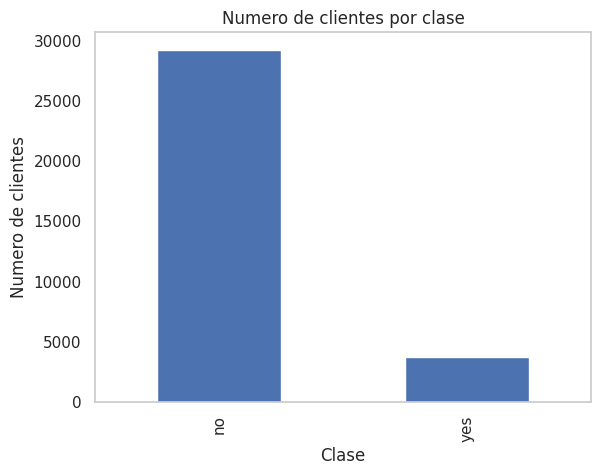

In [19]:
# D1. Escribe el código que muestre:
#  - el número y el porcentaje de clientes de cada clase en ent,
print('Numero de clientes por clase:')
print(ent['y'].value_counts())
print()
print('Porcentaje de clientes por clase:')
print(ent['y'].value_counts(normalize=True))
print()
#  - la razón entre la clase mayoritaria y la minoritaria,
print('Razon entre clase mayoritaria y minoritaria:')
print(ent['y'].value_counts(normalize=True).max() / ent['y'].value_counts(normalize=True).min())
print()
#  - la exactitud de responder siempre "no",
print('Exactitud de responder siempre "no":')
print(ent['y'].value_counts(normalize=True)['no'])
print()
#  - una gráfica de barras con el número de clientes por clase.
ent['y'].value_counts().plot(kind='bar')
plt.xlabel('Clase')
plt.ylabel('Numero de clientes')
plt.title('Numero de clientes por clase')
plt.grid(False)
plt.show()

**Tu observación.**

* **Comparación con predicciones:** En la Parte A predije de forma muy optimista que el porcentaje de contratación rondaría el 30%, cuando en la realidad de este conjunto de entrenamiento es de solo el **11.27%**. Asimismo, en la Parte D predije que un modelo de respuesta constante `no` tendría 100% de exactitud; sin embargo, la métrica real nos muestra que alcanza un **88.73%**.
* **Implicaciones para la evaluación del modelo:**
  1. **Inutilidad de la Exactitud (Accuracy):** No podemos evaluar el modelo usando únicamente la exactitud global. Un modelo completamente inútil que prediga que nadie va a contratar ya tiene un 88.73% de exactitud.
  2. **Métricas alternativas:** Necesitaremos enfocar la evaluación en métricas específicas para clases minoritarias desbalanceadas, tales como la **Sensibilidad (Recall)**, **Precisión** y la métrica **F1-Score** o el área bajo la curva **ROC (AUC)**.
  3. **Estrategia de modelado:** Es muy probable que se requieran técnicas de balanceo de clases (como sobremuestreo SMOTE, submuestreo, o ajuste de pesos en los algoritmos) para evitar que el modelo ignore por completo a los clientes que sí contratan.

### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.

**Tu predicción.** ¿Cuáles de las variables numéricas esperas que más difieran entre quienes contratan y quienes no? Escribe tu respuesta aquí, antes de ejecutar la celda de código.


Espero que la variable numerica que difiere mas de quienes contratan y quienes no sea `duration`.

Mediana de cada variable numerica por clase de y:
      age  duration  campaign  pdays  previous  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed
y                                                                                                                  
no   38.0     164.0       2.0  999.0       0.0           1.1          93.918          -41.8      4.857       5195.8
yes  37.0     448.0       2.0  999.0       0.0          -1.8          93.200          -40.4      1.266       5099.1

Diagramas de caja de age, duration & cons.price.idx:


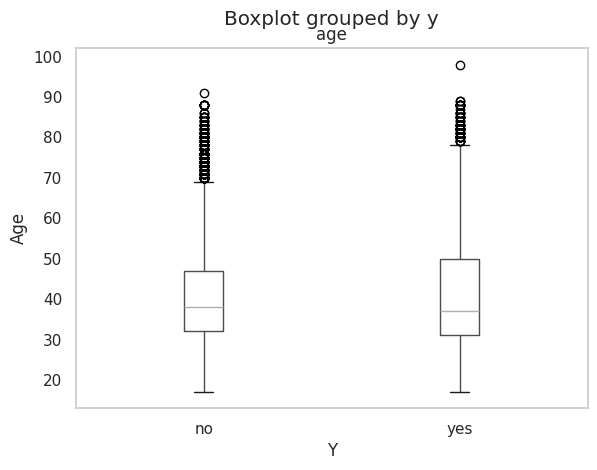

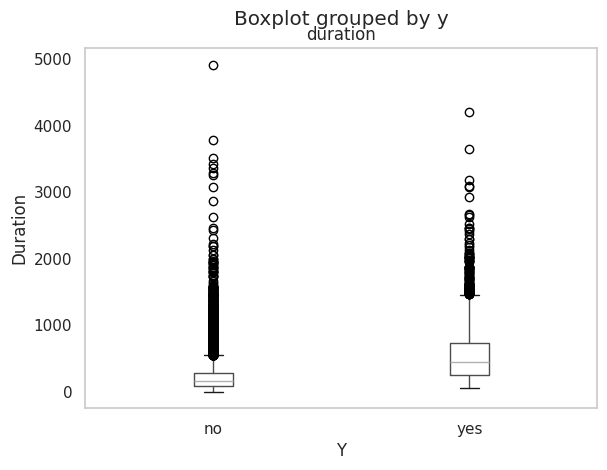

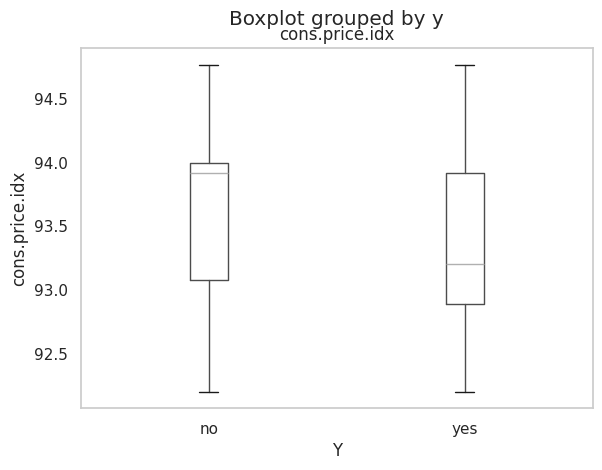

In [29]:
# D2. Escribe el código que muestre:
#  - la mediana de cada variable numérica (lista numericas) por clase de y,
print('Mediana de cada variable numerica por clase de y:')
print(ent.groupby('y')[numericas].median())
print()
#  - diagramas de caja por clase de y de al menos tres variables numéricas que elijas.
print('Diagramas de caja de age, duration & cons.price.idx:')

ent.boxplot(column=['age'], by='y')
plt.ylabel('Age')
plt.xlabel('Y')
plt.grid(False)
plt.show()
ent.boxplot(column=['duration'], by='y')
plt.ylabel('Duration')
plt.xlabel('Y')
plt.grid(False)
plt.show()
ent.boxplot(column=['cons.price.idx'], by='y')
plt.ylabel('cons.price.idx')
plt.xlabel('Y')
plt.grid(False)
plt.show()

**Tu observación.**

* **Variables que separan claramente las clases:**
  * `duration`: Como se predijo, es la variable con mayor poder de separación. Los clientes que contratan (`yes`) tienen una mediana de duración de **448 segundos** (~7.5 minutos), en contraste con los **164 segundos** (~2.7 minutos) de quienes no contratan (`no`).
  * `euribor3m` y `emp.var.rate`: Muestran diferencias drásticas. La mediana del Euribor para quienes contratan es de **1.266** frente a **4.857** para los que no. Similarmente, la tasa de variación del empleo es notablemente menor en el grupo de éxito (**-1.8** vs. **1.1**). Esto sugiere que las condiciones macroeconómicas (tasas bajas y recesión/estabilidad fría) se asocian a una mayor aceptación del depósito.
  * `nr.employed`: Muestra una menor cantidad de empleados activos en el grupo que contrata (mediana de **5099.1** vs. **5195.8**).

* **Variables que NO separan las clases:**
  * `age`: Las medianas de edad son sumamente similares (**37 años** para quienes contratan vs. **38 años** para quienes no), indicando que la edad por sí sola no es un diferenciador directo.
  * `campaign`: Ambos grupos registran una mediana de **2.0** contactos, lo que significa que el esfuerzo promedio de llamadas repetidas en esta campaña es idéntico para ambos resultados.
  * `pdays` y `previous`: No reflejan separación en sus medianas debido a la enorme cantidad de valores por defecto (`999` y `0` respectivamente), por lo que requieren de un análisis complementario.

### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** ¿Qué variables numéricas esperas que tengan más registros fuera de los límites de Tukey? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

In [30]:
# D3. Escribe el código que calcule, con ent, los límites inferior y superior de Tukey
# de cada variable de la lista numericas y muestre cuántos registros quedan fuera de ellos por variable.

for col in numericas:
    q1 = ent[col].quantile(0.25)
    q3 = ent[col].quantile(0.75)
    iqr = q3 - q1

    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr

    fuera_inf = (ent[col] < lim_inf).sum()
    fuera_sup = (ent[col] > lim_sup).sum()
    total_fuera = fuera_inf + fuera_sup
    porcentaje_fuera = (total_fuera / ent.shape[0]) * 100

    print(f"Variable: {col:<15} | IQR: {iqr:>8.3f} | Límites: [{lim_inf:>9.3f}, {lim_sup:>9.3f}] | Atípicos: {total_fuera:>5} ({porcentaje_fuera:>5.2f}%)")

Variable: age             | IQR:   15.000 | Límites: [    9.500,    69.500] | Atípicos:   368 ( 1.12%)
Variable: duration        | IQR:  216.000 | Límites: [ -221.000,   643.000] | Atípicos:  2366 ( 7.18%)
Variable: campaign        | IQR:    2.000 | Límites: [   -2.000,     6.000] | Atípicos:  1916 ( 5.81%)
Variable: pdays           | IQR:    0.000 | Límites: [  999.000,   999.000] | Atípicos:  1226 ( 3.72%)
Variable: previous        | IQR:    0.000 | Límites: [    0.000,     0.000] | Atípicos:  4534 (13.76%)
Variable: emp.var.rate    | IQR:    3.200 | Límites: [   -6.600,     6.200] | Atípicos:     0 ( 0.00%)
Variable: cons.price.idx  | IQR:    0.919 | Límites: [   91.697,    95.373] | Atípicos:     0 ( 0.00%)
Variable: cons.conf.idx   | IQR:    6.300 | Límites: [  -52.150,   -26.950] | Atípicos:   359 ( 1.09%)
Variable: euribor3m       | IQR:    3.617 | Límites: [   -4.081,    10.386] | Atípicos:     0 ( 0.00%)
Variable: nr.employed     | IQR:  129.000 | Límites: [ 4905.600,  5421.60

**Tu respuesta.** ¿Eliminarías los registros atípicos de alguna variable? Justifica por variable con lo que sabes de su significado. Escribe tu respuesta aquí.

**Respuesta:** **No eliminaría los registros atípicos** de ninguna de las variables, ya que no representan errores de captura sino comportamientos reales e informativos del dominio del negocio:

1. **`pdays` (3.72%) y `previous` (13.76%):** Al tener un IQR de 0 (debido a que la gran mayoría de los clientes nunca fueron contactados antes y tienen `999` o `0`), cualquier cliente que sí haya tenido contacto previo es clasificado matemáticamente como "atípico". Sin embargo, este es un evento de negocio real y sumamente valioso para predecir si volverán a contratar.
2. **`duration` (7.18%):** Las llamadas de más de 643 segundos (~10.7 minutos) son atípicas matemáticamente, pero es en estas conversaciones largas donde se concreta el interés y se cierra la venta del depósito. Eliminar estos registros sería borrar los casos de éxito más claros.
3. **`campaign` (5.81%):** Clientes que recibieron más de 6 llamadas reflejan la insistencia de la campaña comercial. Es una conducta de marketing esperada y real.
4. **`age` (1.12%):** Clientes mayores de 69.5 años son personas de la tercera edad reales. Retirarlos sesgaría el análisis para este segmento demográfico que a menudo cuenta con ahorros para depósitos a plazo.

### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.** ¿Cuál transformación, raíz cuadrada o logaritmo (`np.log1p`), reducirá más la asimetría de `campaign`? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Raiz cuadrada reducira mas la asimetria.

Tabla comparativa de asimetrías:


,Asimetría Original,Raíz Cuadrada,Logaritmo (log1p)
age,0.760819,0.426057,0.132406
duration,3.326612,1.203716,-0.430172
campaign,4.742537,2.162976,1.350996


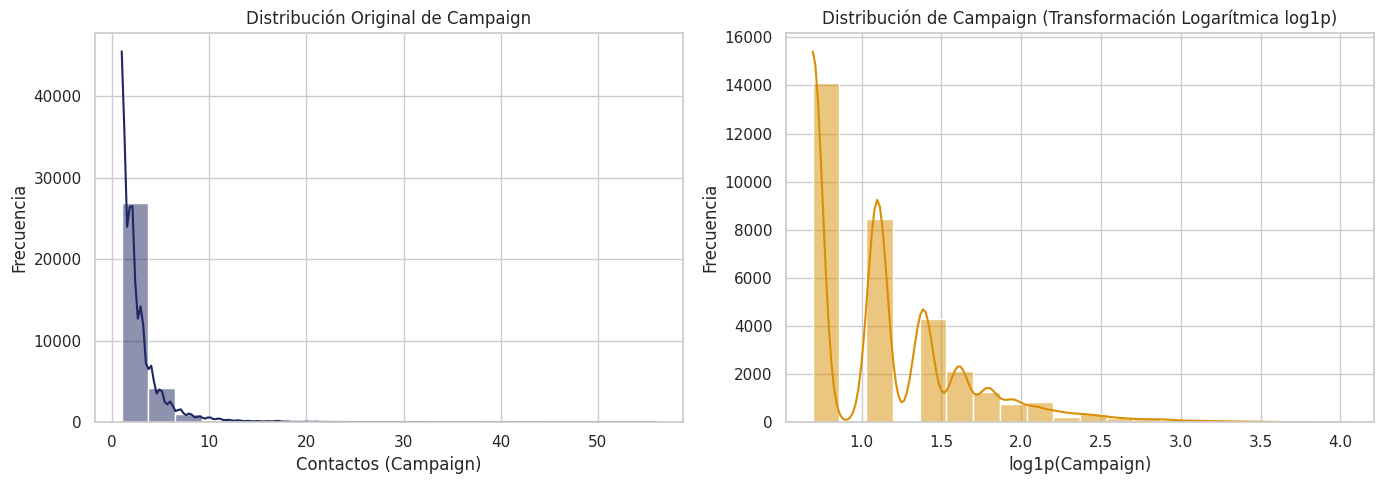

In [38]:
# D4. Escribe el código que muestre una tabla con la asimetría original, con raíz cuadrada y con
# logaritmo (np.log1p) de las variables age, duration y campaign, calculada con ent.
# Después grafica los histogramas de campaign: original y transformada.


vars_analisis = ['age', 'duration', 'campaign']

# Cálculo de asimetrías
skew_original = ent[vars_analisis].skew()
skew_sqrt = np.sqrt(ent[vars_analisis]).skew()
skew_log = np.log1p(ent[vars_analisis]).skew()

# Crear DataFrame comparativo
tabla_asimetria = pd.DataFrame({
    'Asimetría Original': skew_original,
    'Raíz Cuadrada': skew_sqrt,
    'Logaritmo (log1p)': skew_log
})

print("Tabla comparativa de asimetrías:")
display(tabla_asimetria)
print("\n")

# Graficar los histogramas de campaign
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma Original
sns.histplot(ent['campaign'], kde=True, ax=axes[0], color=AZUL, bins=20)
axes[0].set_title('Distribución Original de Campaign')
axes[0].set_xlabel('Contactos (Campaign)')
axes[0].set_ylabel('Frecuencia')

# Histograma Transformado con Logaritmo (log1p reduce mejor la asimetría que sqrt)
sns.histplot(np.log1p(ent['campaign']), kde=True, ax=axes[1], color=NARANJA, bins=20)
axes[1].set_title('Distribución de Campaign (Transformación Logarítmica log1p)')
axes[1].set_xlabel('log1p(Campaign)')
axes[1].set_ylabel('Frecuencia')


plt.tight_layout()
plt.show()

**Tu observación.** Reporta las asimetrías y decide qué transformación, si alguna, aplicarías a cada variable. Escribe tu respuesta aquí y compárala con tu predicción.

**Respuesta y Observaciones:**

* **Análisis de `campaign`:**
  * **Original:** 4.74 (altamente asimétrica a la derecha).
  * **Raíz Cuadrada:** 2.16.
  * **Logaritmo (`log1p`):** 1.35.
  * *Comparación con la predicción:* Mi predicción de que la raíz cuadrada reduciría más la asimetría resultó ser incorrecta. La transformación **logarítmica (`log1p`) fue significativamente más efectiva** reduciendo la asimetría, logrando un valor mucho más cercano a una distribución simétrica, lo cual se corrobora en el gráfico comparativo generado.

* **Análisis de `duration`:**
  * **Original:** 3.32 (sesgo fuerte hacia llamadas cortas).
  * **Logaritmo (`log1p`):** -0.43 (excelente aproximación a una distribución simétrica, pues está muy cercano a 0).

* **Análisis de `age`:**
  * **Original:** 0.76 (asimetría leve/moderada).
  * **Logaritmo (`log1p`):** 0.13.

**Decisión de transformación:**
Para modelos que sean sensibles a la escala y a la asimetría aplicaría la **transformación logarítmica (`np.log1p`)** tanto para `campaign` como para `duration` debido a su notable impacto corrector de sesgo.

## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** ¿Qué variable categórica esperas que tenga las categorías con mayor tasa de contratación? ¿Y cuáles esperas que casi no separen las clases? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Espero que la variable con mayor tasa de contratacion sea `education`. Y las que no separaran casi las clases seran `married` y `job`.

In [50]:
# E1. Escribe el código que muestre:
#  - el número de categorías de cada variable de la lista categoricas,
print('Número de categorías de cada variable categórica:')
print(df[categoricas].nunique())
print()

#  - la tasa global de contratación en ent.
print('Tasa global de contratación:')
print(ent['suscribe'].mean())
print()

Número de categorías de cada variable categórica:
job            12
marital         4
education       8
default         3
housing         3
loan            3
contact         2
month          10
day_of_week     5
poutcome        3
dtype: int64

Tasa global de contratación:
0.11265553869499241



In [51]:
# E2. Escribe el código que construya una tabla con el número de clientes y la tasa de contratación (en %)
# de cada categoría de cada variable de categoricas.

# 1. Transformar el DataFrame para agrupar las columnas categóricas
cat_df = ent[categoricas + ['suscribe']].melt(id_vars='suscribe', var_name='Variable', value_name='Categoria')

# 2. Agrupar y calcular conteo y tasa de contratación en %
tabla_cat = cat_df.groupby(['Variable', 'Categoria'])['suscribe'].agg(
    Clientes='count',
    Tasa_Contratacion=lambda x: x.mean() * 100
).reset_index()

# --- PRESENTACIÓN DE RESULTADOS ---

# a) Las 12 categorías con mayor tasa de contratación
print("=== 12 CATEGORÍAS CON MAYOR TASA DE CONTRATACIÓN ===")
display(tabla_cat.sort_values(by='Tasa_Contratacion', ascending=False).head(12))
print("\n")

# b) Las 8 categorías con menor tasa de contratación
print("=== 8 CATEGORÍAS CON MENOR TASA DE CONTRATACIÓN ===")
display(tabla_cat.sort_values(by='Tasa_Contratacion', ascending=True).head(8))
print("\n")

# c) Tablas específicas solicitadas
for var in ['default', 'housing', 'loan', 'day_of_week']:
    print(f"=== Tabla para {var} ===")
    display(tabla_cat[tabla_cat['Variable'] == var].sort_values(by='Tasa_Contratacion', ascending=False))
    print("\n")

=== 12 CATEGORÍAS CON MAYOR TASA DE CONTRATACIÓN ===


,Variable,Categoria,Clientes,Tasa_Contratacion
52,poutcome,success,1105,64.886878
42,month,dec,143,50.349650
45,month,mar,436,49.770642
49,month,sep,464,44.612069
48,month,oct,587,43.270869
29,job,student,711,30.520394
26,job,retired,1366,25.475842
40,month,apr,2085,20.479616
14,education,illiterate,16,18.750000
39,marital,unknown,65,16.923077




=== 8 CATEGORÍAS CON MENOR TASA DE CONTRATACIÓN ===


,Variable,Categoria,Clientes,Tasa_Contratacion
9,default,yes,3,0.000000
8,default,unknown,6940,5.201729
1,contact,telephone,12042,5.298123
46,month,may,11011,6.348197
22,job,blue-collar,7441,6.921113
12,education,basic.9y,4826,7.646084
28,job,services,3196,7.947434
11,education,basic.6y,1865,8.364611




=== Tabla para default ===


...

,Variable,Categoria,Clientes,Tasa_Contratacion
20,housing,yes,17254,11.556740
19,housing,unknown,796,11.306533
18,housing,no,14900,10.926174




=== Tabla para loan ===


,Variable,Categoria,Clientes,Tasa_Contratacion
34,loan,unknown,796,11.306533
33,loan,no,27131,11.271240
35,loan,yes,5023,11.228350




=== Tabla para day_of_week ===


,Variable,Categoria,Clientes,Tasa_Contratacion
4,day_of_week,thu,6857,12.002333
5,day_of_week,tue,6444,11.607697
6,day_of_week,wed,6515,11.557943
2,day_of_week,fri,6322,10.914268
3,day_of_week,mon,6812,10.246624


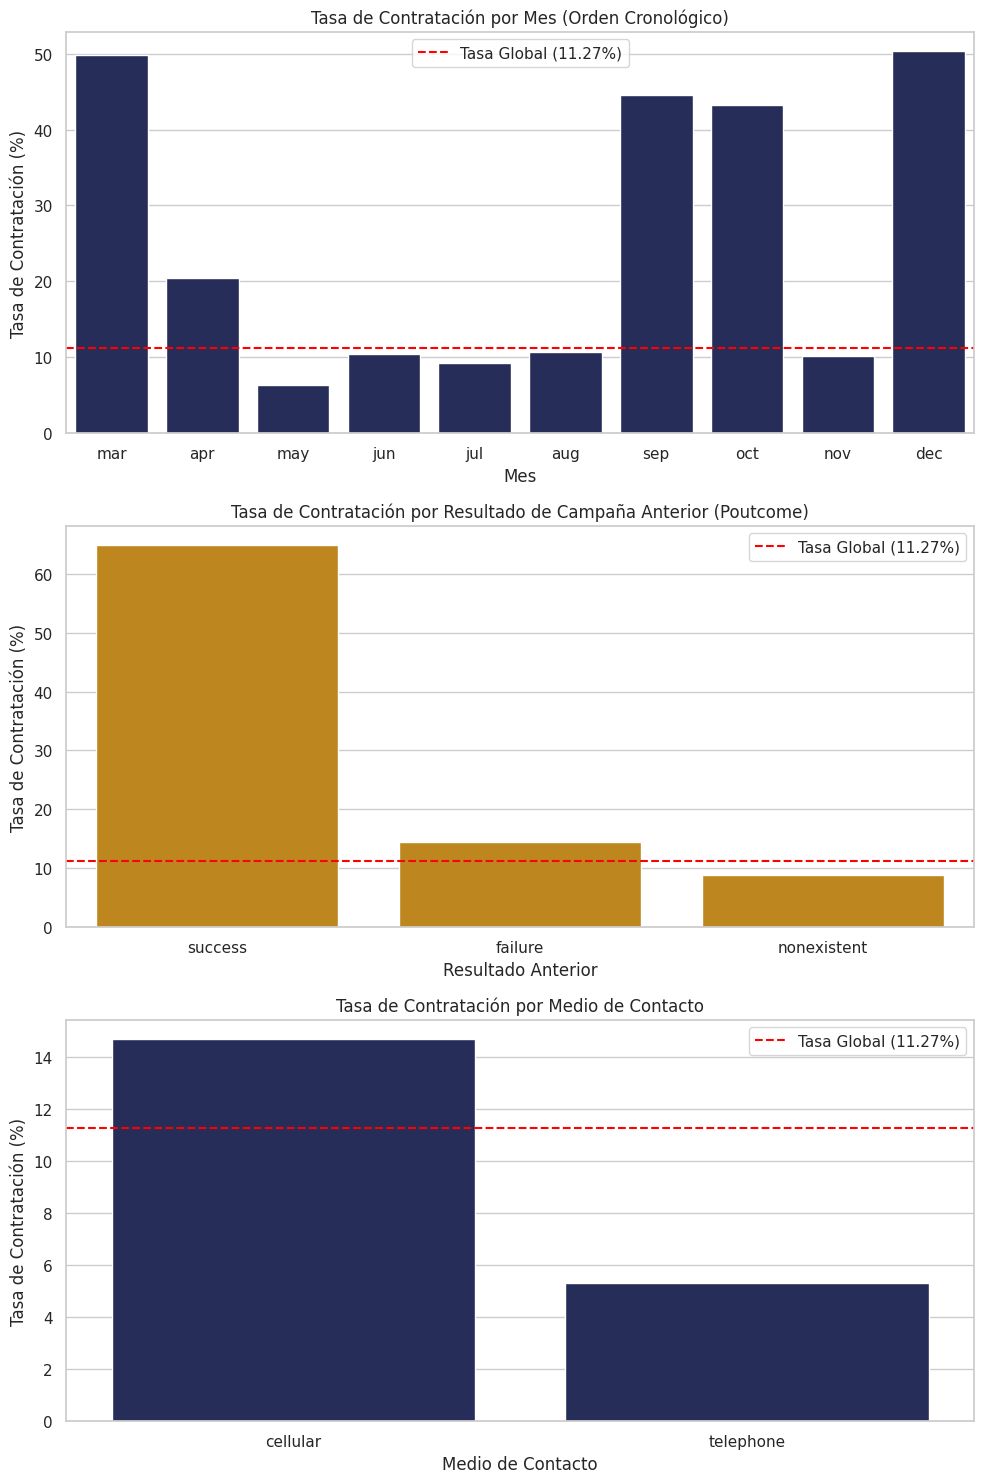

In [52]:
# E3. Escribe el código que grafique la tasa de contratación por categoría de month (en orden
# cronológico: mar, apr, may, jun, jul, aug, sep, oct, nov, dec), poutcome y contact,
# con una línea horizontal en la tasa global.

tasa_global_pct = ent['suscribe'].mean() * 100
orden_meses = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']

fig, axes = plt.subplots(3, 1, figsize=(10, 15))


# 1. Gráfico para Month
tabla_month = tabla_cat[tabla_cat['Variable'] == 'month'].copy()
tabla_month['Categoria'] = pd.Categorical(tabla_month['Categoria'], categories=orden_meses, ordered=True)
tabla_month = tabla_month.sort_values('Categoria')

sns.barplot(x='Categoria', y='Tasa_Contratacion', data=tabla_month, ax=axes[0], color=AZUL)
axes[0].axhline(tasa_global_pct, color='red', linestyle='--', label=f'Tasa Global ({tasa_global_pct:.2f}%)')
axes[0].set_title('Tasa de Contratación por Mes (Orden Cronológico)')
axes[0].set_ylabel('Tasa de Contratación (%)')
axes[0].set_xlabel('Mes')
axes[0].legend()

# 2. Gráfico para Poutcome
tabla_poutcome = tabla_cat[tabla_cat['Variable'] == 'poutcome'].sort_values(by='Tasa_Contratacion', ascending=False)
sns.barplot(x='Categoria', y='Tasa_Contratacion', data=tabla_poutcome, ax=axes[1], color=NARANJA)
axes[1].axhline(tasa_global_pct, color='red', linestyle='--', label=f'Tasa Global ({tasa_global_pct:.2f}%)')
axes[1].set_title('Tasa de Contratación por Resultado de Campaña Anterior (Poutcome)')
axes[1].set_ylabel('Tasa de Contratación (%)')
axes[1].set_xlabel('Resultado Anterior')
axes[1].legend()


# 3. Gráfico para Contact
tabla_contact = tabla_cat[tabla_cat['Variable'] == 'contact'].sort_values(by='Tasa_Contratacion', ascending=False)
sns.barplot(x='Categoria', y='Tasa_Contratacion', data=tabla_contact, ax=axes[2], color=AZUL)
axes[2].axhline(tasa_global_pct, color='red', linestyle='--', label=f'Tasa Global ({tasa_global_pct:.2f}%)')
axes[2].set_title('Tasa de Contratación por Medio de Contacto')
axes[2].set_ylabel('Tasa de Contratación (%)')
axes[2].set_xlabel('Medio de Contacto')
axes[2].legend()
plt.tight_layout()
plt.show()

**Tu observación.** Identifica las categorías con mayor y menor tasa, con su tasa y su número de clientes, y las variables que casi no separan las clases. Escribe tu respuesta aquí y compárala con tu predicción.

**Respuesta y Observaciones:**

* **Categorías con mayor tasa de contratación (Éxito sobresaliente):**
  1. **`poutcome == success`:** Tasa de éxito del **64.89%** (1,105 clientes). Es, por mucho, el indicador individual más fuerte.
  2. **`month == dec`:** Tasa de éxito del **50.35%** (143 clientes).
  3. **`month == mar`:** Tasa de éxito del **49.77%** (436 clientes).
  4. **`month == sep`:** Tasa de éxito del **44.61%** (464 clientes).
  5. **`month == oct`:** Tasa de éxito del **43.27%** (587 clientes).
  6. **`job == student`:** Tasa de éxito del **30.52%** (711 clientes).
  7. **`job == retired`:** Tasa de éxito del **25.48%** (1,366 clientes).

* **Categorías con menor tasa de contratación (Bajo rendimiento):**
  1. **`default == yes`:** Tasa de éxito del **0.00%** (3 clientes).
  2. **`default == unknown`:** Tasa de éxito del **5.20%** (6,940 clientes).
  3. **`contact == telephone`:** Tasa de éxito del **5.30%** (12,042 clientes).
  4. **`month == may`:** Tasa de éxito del **6.35%** (¡A pesar de tener el mayor volumen con 11,011 clientes!).
  5. **`job == blue-collar`:** Tasa de éxito del **6.92%** (7,441 clientes).

* **Variables que casi no separan las clases:**
  * **`day_of_week`:** Todas las categorías (lunes a viernes) oscilan estrictamente entre el **10.1%** y el **12.1%**, manteniéndose casi pegadas a la línea de tasa global (11.27%).
  * **`marital`:** Las categorías como `married` (10.23%) y `single` (14.07%) muestran muy poca dispersión respecto al promedio general.
  * **`housing` y `loan`:** Tener o no crédito hipotecario o préstamo personal mantiene tasas de éxito en un rango plano de entre **10.4%** y **11.6%**.

* **Comparación con la predicción:**
  * Mi predicción de que `marital` y `job` casi no separarían las clases fue **parcialmente correcta**: `marital` en efecto no separa casi nada, pero `job` sí tiene subgrupos con excelente separación como `student` (30.52%) y `retired` (25.48%).
  * Erré al predecir que `education` sería la variable principal de éxito; en realidad, el resultado de la campaña previa (`poutcome`) y el mes de contacto (`month`) demostraron tener un impacto predictivo drásticamente superior.

**Tu respuesta.** En `default`, ¿qué indica que la categoría `unknown` tenga una tasa de contratación distinta a la de `no`? ¿Qué hay que cuidar con las categorías `yes` de `default` o `illiterate` de `education`? Escribe tu respuesta aquí.

## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** ¿Qué pares de indicadores económicos (lista `macro`) esperas que estén más correlacionados? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Espero que emp.var.rate y nr.employed esten relacionados.

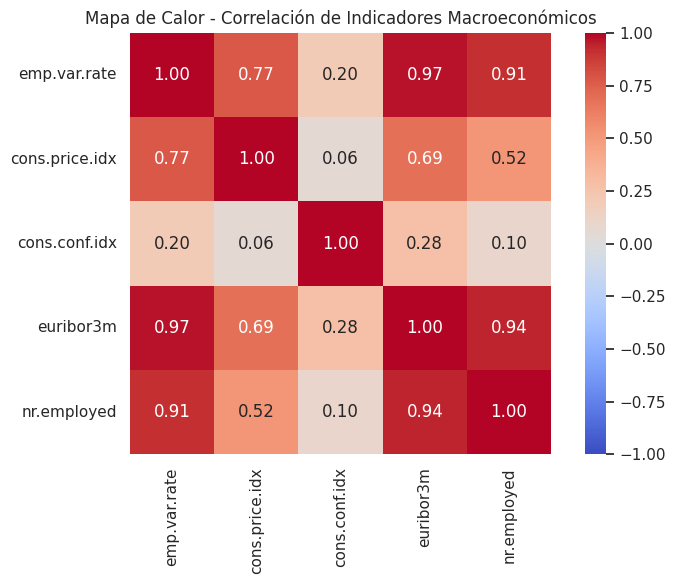

In [54]:
# F1. Escribe el código que muestre un mapa de calor con la matriz de correlación de las variables de la lista macro,
# calculada con ent, con los valores anotados en cada celda.

# Calcular la matriz de correlación de Pearson
matriz_corr = ent[macro].corr()

# Crear el mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, square=True)
plt.title('Mapa de Calor - Correlación de Indicadores Macroeconómicos')
plt.tight_layout()
plt.show()

**Tu observación.** Reporta los pares más correlacionados y la decisión que implican. Escribe tu respuesta aquí y compárala con tu predicción.

**Respuesta y Observaciones:**

* **Pares con correlación extremadamente fuerte (Multicolinealidad crítica):**
  1. **`euribor3m` y `emp.var.rate` (0.97):** Existe una relación casi lineal perfecta positiva entre la tasa de interés Euribor a 3 meses y la variación en la tasa de empleo.
  2. **`euribor3m` y `nr.employed` (0.94):** Relación muy fuerte entre la tasa de interés y el volumen total de empleados contratados.
  3. **`emp.var.rate` y `nr.employed` (0.91):** Relación sumamente predecible entre el número de empleados y su tasa de variación.

* **Comparación con la predicción:**
  * Mi predicción de que estas variables estarían altamente correlacionadas resultó ser correcta. Estos indicadores económicos se mueven de forma coordinada según el ciclo económico nacional.

* **Decisión de modelado implícita:**
  * **Para Modelos Lineales o de Redes Neuronales (Regresión Logística, MLP):** Mantener todas estas variables juntas causaría problemas de **multicolinealidad**, haciendo que los coeficientes del modelo sean inestables e imposibles de interpretar. Se debe aplicar una técnica de selección o reducción de variables para conservar únicamente un representante de este bloque económico (por ejemplo, **`euribor3m`**, que tiene muy buena relación con la tasa de contratación) y eliminar del modelado a las demás variables colineales (`emp.var.rate` y `nr.employed`).
  * **Para Modelos basados en Árboles (XGBoost, Random Forest):** Los árboles de decisión son inmunes a la colinealidad en términos de poder predictivo, pero simplificar el set de datos removiendo variables redundantes mejora la mantenibilidad del modelo.

### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.

In [55]:
# F2. Escribe el código que muestre el resumen estadístico (describe) de duration por clase de y.
print('Resumen estadístico de duration por clase de y:')
print(ent.groupby('y')['duration'].describe())
print()

Resumen estadístico de duration por clase de y:
       count        mean         std   min    25%    50%    75%     max
y                                                                      
no   29238.0  221.148198  208.303557   0.0   95.0  164.0  279.0  4918.0
yes   3712.0  549.398976  397.490060  63.0  252.0  448.0  737.0  4199.0



**Tu respuesta.** ¿Incluirías `duration` como característica de un modelo que se usará para decidir a quién llamar? Justifica con la definición de la variable y con lo observado. Escribe tu respuesta aquí.

**Respuesta corregida:**

**No, no incluiría la variable `duration`** en el modelo predictivo final por las siguientes razones fundamentales de negocio y metodología:

1. **Fuga de información (Data Leakage):** La duración de la llamada es una variable que se genera *durante* el contacto telefónico. Al momento en que el banco necesita usar el modelo predictivo (que es para planificar la campaña y seleccionar la lista de clientes a los que se va a marcar), **esta información aún no existe**. No podemos predecir el futuro usando una variable del futuro.
2. **Relación causa-consecuencia artificial:** Estadísticamente, observamos que quienes contratan tienen llamadas más largas (mediana de 448 segundos vs. 164). Sin embargo, esto es un efecto colateral: la llamada dura más *porque* el cliente está interesado, haciendo preguntas y proporcionando datos para abrir la cuenta. No es que por el simple hecho de mantener a alguien colgado al teléfono 10 minutos se vaya a lograr la venta de forma causal.


**Tu respuesta.** El conjunto está ordenado por fecha y los indicadores económicos varían con el tiempo. ¿Qué implica dividir al azar, como en la parte C, para un modelo que se usará en campañas futuras? Escribe tu respuesta aquí.

**Respuesta:**

Dividir el conjunto de datos al azar cuando existe una estructura inherentemente temporal y macroeconómica tiene implicaciones negativas graves para la validez del modelo:

1. **Fuga de datos temporal (Look-ahead bias / Temporal Leakage):** Al mezclar aleatoriamente observaciones del período 2008-2010, el modelo entrenará con datos del futuro (por ejemplo, finales de 2010) para predecir transacciones que ocurrieron en el pasado (por ejemplo, principios de 2008). En la práctica real, el banco no puede usar información del futuro macroeconómico para predecir hoy.
2. **Evaluación artificialmente optimista:** El test set aleatorio compartirá el mismo contexto económico temporal exacto (como el valor del `euribor3m` de esa misma semana) que el set de entrenamiento. Esto causará que el rendimiento en la métrica de prueba sea excepcionalmente alto, pero es una ilusión.
3. **Pobre generalización en campañas futuras:** Cuando el modelo se despliegue para decidir a quién llamar en una campaña nueva en 2011, se enfrentará a un entorno macroeconómico inédito (nuevas tasas Euribor, inflación y tasas de empleo). Debido a que aprendió correlaciones temporales cruzadas aleatorias, su rendimiento real decaerá bruscamente.
4. **Práctica recomendada:** Para que la evaluación refleje el uso real del negocio, se debió haber realizado una **división basada en tiempo (Time-based split / Out-of-time validation)**: entrenar con el primer 80% de los datos cronológicos e intentar predecir el último 20% temporalmente consecutivo.

## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.

| Hallazgo (con cifra) | Decisión | Se aplica en |
| --- | --- | --- |
| **Fuga de información:** La mediana de `duration` es drásticamente diferente entre clases (448s en *yes* vs. 164s en *no*), pero este dato solo se conoce una vez iniciada/finalizada la llamada. | **Excluir completamente la variable `duration`** del conjunto de entrenamiento de cara al modelo predictivo final. | Modelos |
| **Valores faltantes masivos:** La columna `default` tiene un 20.87% (8,597 filas) de valores registrados como `unknown` con una tasa de contratación del 5.20% (diferente al 12.83% de la categoría `no`). | **Mantener `unknown` como una categoría explícita** en lugar de eliminarla o imputarla con la clase mayoritaria. | Preprocesamiento |
| **Desbalance crítico de clases:** La clase minoritaria (`yes`) representa solo el 11.27% de las observaciones. Un modelo constante que prediga siempre `no` obtendría un 88.73% de exactitud (*accuracy*). | **Descartar la Exactitud (*Accuracy*)** como métrica de optimización y utilizar en su lugar **F1-Score, Recall (Sensibilidad) y AUC-ROC**. | Evaluación |
| **Desbalance crítico de clases:** La razón de desbalance entre la clase mayoritaria y la minoritaria es de 7.88 a 1. | **Aplicar algoritmos con pesos balanceados** (`class_weight='balanced'`) o técnicas de remuestreo (SMOTE) para evitar sesgos hacia el *no*. | Modelos |
| **Multicolinealidad extrema:** Hay correlaciones lineales altísimas en el bloque `macro`: `euribor3m` con `emp.var.rate` (0.97) y con `nr.employed` (0.94). | **Conservar únicamente `euribor3m`** como representante macroeconómico y descartar las otras variables colineales para evitar inestabilidad en modelos lineales. | Preprocesamiento / Modelos |
| **Asimetría extrema a la derecha:** La variable `campaign` presenta una asimetría original severa de 4.74, que se reduce de manera óptima a 1.35 aplicando logaritmo. | **Aplicar transformación logarítmica (`np.log1p`)** a la variable `campaign` (y también a `duration` si se usara en modelos que no sean de árboles). | Preprocesamiento |
| **Ausencia de poder predictivo (Baja varianza):** La variable categórica `day_of_week` mantiene una tasa de conversión plana y uniforme para todos sus días (entre 10.1% y 12.1%), muy cercana a la tasa global de 11.27%. | **Descartar la variable `day_of_week`** del modelo final para reducir dimensionalidad y simplificar el procesamiento. | Preprocesamiento / Modelos |

### G2. Uso de los datos

**Tu respuesta.** En esta actividad, ¿qué partes se hicieron con el conjunto total y cuáles solo con entrenamiento? Explica el criterio. Escribe tu respuesta aquí.

**Respuesta:**

### 1. ¿Qué partes se hicieron con cada conjunto?
* **Con el Conjunto Total (`df`):** Se realizó la **Parte B (Calidad de Datos)**. Evaluamos las dimensiones de la matriz, tipos de datos, conteo de nulos generales, consistencia estructural del dominio (como la relación lógica entre `pdays` y `poutcome`, o filas idénticas duplicadas) y consistencia de rangos demográficos.
* **Con el Conjunto de Entrenamiento (`ent`):** Se realizó desde la **Parte D hasta la Parte G**. Analizamos la distribución del objetivo, calculamos las medianas de las variables continuas agrupadas por clase, calculamos los límites de outlier con Tukey, calculamos la matriz de asimetrías y coeficientes de correlación Pearson, y calculamos las tasas de éxito de las variables categóricas.

### 2. Criterio Metodológico (¿Por qué?)
El criterio fundamental es **prevenir la fuga de datos (*data leakage*)** y garantizar una evaluación futura honesta:

* **El conjunto total** sirve exclusivamente para análisis de **estructura y calidad técnica**. Conocer que una columna tiene duplicados o formatos incorrectos es una propiedad intrínseca del set de datos que no depende del comportamiento o patrones predictivos de la variable `y`.
* **El conjunto de entrenamiento** es el único lugar donde se deben estudiar **asociaciones, estadísticas multivariables y transformaciones**. Si calculamos límites de atípicos (Tukey), asimetrías, imputaciones, o correlaciones usando el conjunto completo, estaríamos permitiendo que el conocimiento del conjunto de prueba (*test set*) altere los parámetros de preprocesamiento de nuestro entrenamiento. Esto generaría una evaluación irrealmente optimista del modelo sobre los datos de prueba, comprometiendo su validez.

**Tu respuesta.** Si hubieras explorado también el conjunto de prueba, ¿qué decisión de tu hoja podría quedar sesgada y cómo se reflejaría en la evaluación final? Escribe tu respuesta aquí.

**Respuesta:**

Si hubiéramos explorado el conjunto de prueba junto con el de entrenamiento antes de estructurar la hoja de decisiones, se habrían producido varios sesgos críticos de **fuga de datos (data leakage)**